In [4]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '7'



import torch
from evo2 import Evo2
from Bio import SeqIO
import numpy as np
from pathlib import Path
from tqdm import tqdm
import random

from LogitLnes_evo2_utils import find_norm_and_unembed, evo2_logit_lens, plot_logit_lens_evo2_annotated, plot_logit_lens_evo2_averaged, plot_logit_lens_multi_model


In [5]:
NUCLEOTIDES = ['A', 'C', 'G', 'T']
BUFFER_LEN = 24
LABEL_LEN  = 24

def sample_label_nucleotides():
    """
    Sample three distinct nucleotides without replacement from {A, C, G, T}:
      - buffer_nuc  : used for the 24-nt spacer between a sequence and its label
      - label_nuc_0 : label nucleotide representing class 0
      - label_nuc_1 : label nucleotide representing class 1

    Re-sampling per trial ensures no fixed nucleotide is systematically
    associated with a particular class, eliminating nucleotide-bias artifacts.

    Returns
    -------
    buffer_nuc  : str   single nucleotide character for the buffer
    label_nuc_0 : str   single nucleotide character for class 0
    label_nuc_1 : str   single nucleotide character for class 1
    """
    chosen = random.sample(NUCLEOTIDES, 3)
    return chosen[0], chosen[1], chosen[2]

def make_label_string(buffer_nuc, label_nuc, buffer_len=None, label_len=None):
    """
    Construct the label suffix appended to each in-context training example.

    Structure:  [buffer_nuc × buffer_len] + [label_nuc × label_len]

    The buffer provides a clear separator between the biological sequence and
    the classification label, reducing any ambiguity at the junction.

    Parameters
    ----------
    buffer_nuc  : str   nucleotide character repeated buffer_len times
    label_nuc   : str   nucleotide character repeated label_len times (the class token)
    buffer_len  : int   length of the buffer region (defaults to BUFFER_LEN if None)
    label_len   : int   length of the label region  (defaults to LABEL_LEN  if None)

    Returns
    -------
    str : the full label suffix (buffer + label run)
    """
    if buffer_len is None:
        buffer_len = BUFFER_LEN
    if label_len is None:
        label_len = LABEL_LEN
    return buffer_nuc * buffer_len + label_nuc * label_len

def build_few_shot_prefix(
    context_examples,
    buffer_nuc,
    label_nuc_0,
    label_nuc_1,
    buffer_len=None,
    label_len=None,
):
    """
    Construct the few-shot prefix from in-context training examples.

    Each example is: <sequence><buffer_nuc × buffer_len><label_nuc × label_len>

    The label nucleotide depends on the example's class:
      - class 0 → label_nuc_0
      - class 1 → label_nuc_1

    Parameters
    ----------
    context_examples : list of (sequence: str, class_idx: int)
        Balanced list of training sequences and their class indices (0 or 1).
    buffer_nuc       : str   buffer nucleotide (see sample_label_nucleotides)
    label_nuc_0      : str   label nucleotide for class 0
    label_nuc_1      : str   label nucleotide for class 1
    buffer_len  : int   length of buffer region (defaults to BUFFER_LEN if None)
    label_len   : int   length of label region  (defaults to LABEL_LEN  if None)

    Returns
    -------
    str : concatenated few-shot prefix (no separator between examples)
    """
    if buffer_len is None:
        buffer_len = BUFFER_LEN
    if label_len is None:
        label_len = LABEL_LEN
    label_nucs = [label_nuc_0, label_nuc_1]
    parts = []
    for seq, class_idx in context_examples:
        label_suffix = make_label_string(buffer_nuc, label_nucs[class_idx], buffer_len, label_len)
        parts.append(seq + label_suffix)
    return "".join(parts)

def build_candidate_prompt(prefix, query_seq, buffer_nuc, candidate_label_nuc,
                            buffer_len=None, label_len=None):
    """
    Build a complete candidate prompt for perplexity scoring.

    Structure:
        <few-shot prefix> + <query_seq> + <buffer> + <candidate label run>

    Two candidate prompts are built per test query: one for class 0 and one
    for class 1.  The model's perplexity is computed over the final label_len
    tokens (the label run only, not the buffer), and the candidate with lower
    perplexity is selected as the prediction.

    Parameters
    ----------
    prefix               : str   pre-built few-shot prefix
    query_seq            : str   the test sequence to classify
    buffer_nuc           : str   buffer nucleotide
    candidate_label_nuc  : str   label nucleotide for this candidate class
    buffer_len           : int   length of buffer region (defaults to BUFFER_LEN if None)
    label_len            : int   length of label region  (defaults to LABEL_LEN  if None)

    Returns
    -------
    str : full prompt string including the candidate label
    """
    if buffer_len is None:
        buffer_len = BUFFER_LEN
    if label_len is None:
        label_len = LABEL_LEN
    label_suffix = make_label_string(buffer_nuc, candidate_label_nuc, buffer_len, label_len)
    return prefix + query_seq + label_suffix


In [6]:
# ── Real sequences ────────────────────────────────────────────────────
# microRNA sequences

# --- Data ---
train_examples = [
    ("UUCAUUUUGAAAAUAGGCAUUG", 0),   # class 0 = mrna
    ("TCGCAGAATTTGCTTCGCGAG", 1),   # class 1 = neutral
    ("UGGCAAACGUGGAAGCCGAGA", 0),
    ("ATGCAACGCCGATCAAACTAG", 1),
]
query_seq = "ACAUAGGGUCCAAAGCCAUUG"  # class = 0

# --- Sample nucleotide assignments for this trial ---
buffer_nuc, label_nuc_0, label_nuc_1 = sample_label_nucleotides()
print(f"buffer={buffer_nuc}, label_0={label_nuc_0}, label_1={label_nuc_1}")

# --- Build the few-shot prefix ---
prefix = build_few_shot_prefix(train_examples, buffer_nuc, label_nuc_0, label_nuc_1)

# --- Build both candidate prompts ---
prompt_0 = build_candidate_prompt(prefix, query_seq, buffer_nuc, label_nuc_0)
prompt_1 = build_candidate_prompt(prefix, query_seq, buffer_nuc, label_nuc_1)

sequence = prompt_0[:-23]

# AMR sequences
# # Path to your multi-FASTA file
# fasta_file = 'data/AMR.genes.fna'

# # Process each sequence in the FASTA file
# print(f"Processing sequences from {fasta_file}...")

# for record in tqdm(SeqIO.parse(fasta_file, "fasta")):
#     seq_id = record.id
#     sequence = str(record.seq).upper()
#     seq_length = len(string)
#     break

# TATA sequences
# Path to your multi-FASTA file
# fasta_file = 'data/tata_box_files/Hsapiens_TATA.fna'

# Process each sequence in the FASTA file
# print(f"Processing sequences from {fasta_file}...")
# for record in tqdm(SeqIO.parse(fasta_file, "fasta")):
#    seq_id = record.id
#    sequence = str(record.seq).upper()
#    seq_length = len(string)
#    break



buffer=G, label_0=C, label_1=A


In [3]:
# ── Example sequences ────────────────────────────────────────────────────
# Promoter-like TATA-box followed by a coding-region stub
# sequence = 'TATAAAAGGCTAGCATGCGTACGATCGATCGATCGTTAG'

# Splice-donor / acceptor motif (GT…AG rule)
# sequence = 'ATCGATCGATCGGTAAGTATCGATCGATCGATCGATCGAGC'

# Simple repetitive element
# sequence = 'ATGATGATGATGATGATGATGATGATGATGATGATGATGATG'

# Coding sequence: ATG … stop codon TGA
# sequence = 'ATGCGTACGATCGATCGATCGTTCAACGATCGATCGATCGTGA'

# Short random sequence
# sequence = "ATGCGT"

In [8]:
mdl_id = 'evo2_7b'

multi_seq_comp = False

In [9]:
evo2_model = Evo2(mdl_id)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Found complete file in repo: evo2_7b.pt


100%|████████████████████████████████████████████████████████| 32/32 [00:00<00:00, 286.25it/s]


Extra keys in state_dict: {'blocks.10.mixer.attn._extra_state', 'blocks.31.mixer.dense._extra_state', 'blocks.17.mixer.attn._extra_state', 'blocks.6.mixer.mixer.filter.t', 'blocks.16.mixer.mixer.filter.t', 'blocks.2.mixer.mixer.filter.t', 'blocks.27.mixer.mixer.filter.t', 'blocks.24.mixer.attn._extra_state', 'blocks.10.mixer.dense._extra_state', 'unembed.weight', 'blocks.17.mixer.dense._extra_state', 'blocks.30.mixer.mixer.filter.t', 'blocks.3.mixer.dense._extra_state', 'blocks.23.mixer.mixer.filter.t', 'blocks.31.mixer.attn._extra_state', 'blocks.3.mixer.attn._extra_state', 'blocks.20.mixer.mixer.filter.t', 'blocks.24.mixer.dense._extra_state', 'blocks.9.mixer.mixer.filter.t', 'blocks.13.mixer.mixer.filter.t'}


/scratch/ceresma/envs/evo2/lib/python3.11/site-packages/transformer_engine/pytorch/module/base.py:630: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(state

In [11]:
input_ids = torch.tensor(
    evo2_model.tokenizer.tokenize(sequence),
    dtype=torch.int,
).unsqueeze(0).to('cuda')

outputs, _ = evo2_model(input_ids)
logits = outputs[0]

print('Logits: ', logits)
print('Shape (batch, length, vocab): ', logits.shape)

Logits:  tensor([[[  4.9375,  22.1250,  22.1250,  ...,  22.1250,  22.1250,  22.1250],
         [  4.2500,  22.7500,  22.7500,  ...,  22.7500,  22.7500,  22.8750],
         [ -7.6562, -13.8125, -13.8125,  ..., -13.8125, -13.8125, -13.8125],
         ...,
         [ -7.4688, -20.6250, -20.6250,  ..., -20.6250, -20.6250, -20.6250],
         [ -7.5312, -20.7500, -20.7500,  ..., -20.7500, -20.7500, -20.7500],
         [ -8.3750, -22.0000, -22.0000,  ..., -22.0000, -22.0000, -22.0000]]],
       device='cuda:0', dtype=torch.bfloat16)
Shape (batch, length, vocab):  torch.Size([1, 323, 512])


In [12]:
input_ids, results = evo2_logit_lens(evo2_model, sequence)

Found norm at: model.norm
Found unembed at: model.unembed
Copied norm: param='scale', shape=torch.Size([4096]), eps=1e-06
Found norm at: model.norm
Found unembed at: model.unembed
Unembed is bound to: VocabParallelEmbedding
Found weight 'weight': torch.Size([512, 4096]) on cuda:0


Saved to images/evo2_7b_logit_lens_top1




In [13]:
# Color by top-1 confidence, annotate with top-1 token
plot_logit_lens_evo2_annotated(
    sequence, 
    results,
    save_path=f"images/{mdl_id}_logit_lens_top1"
)

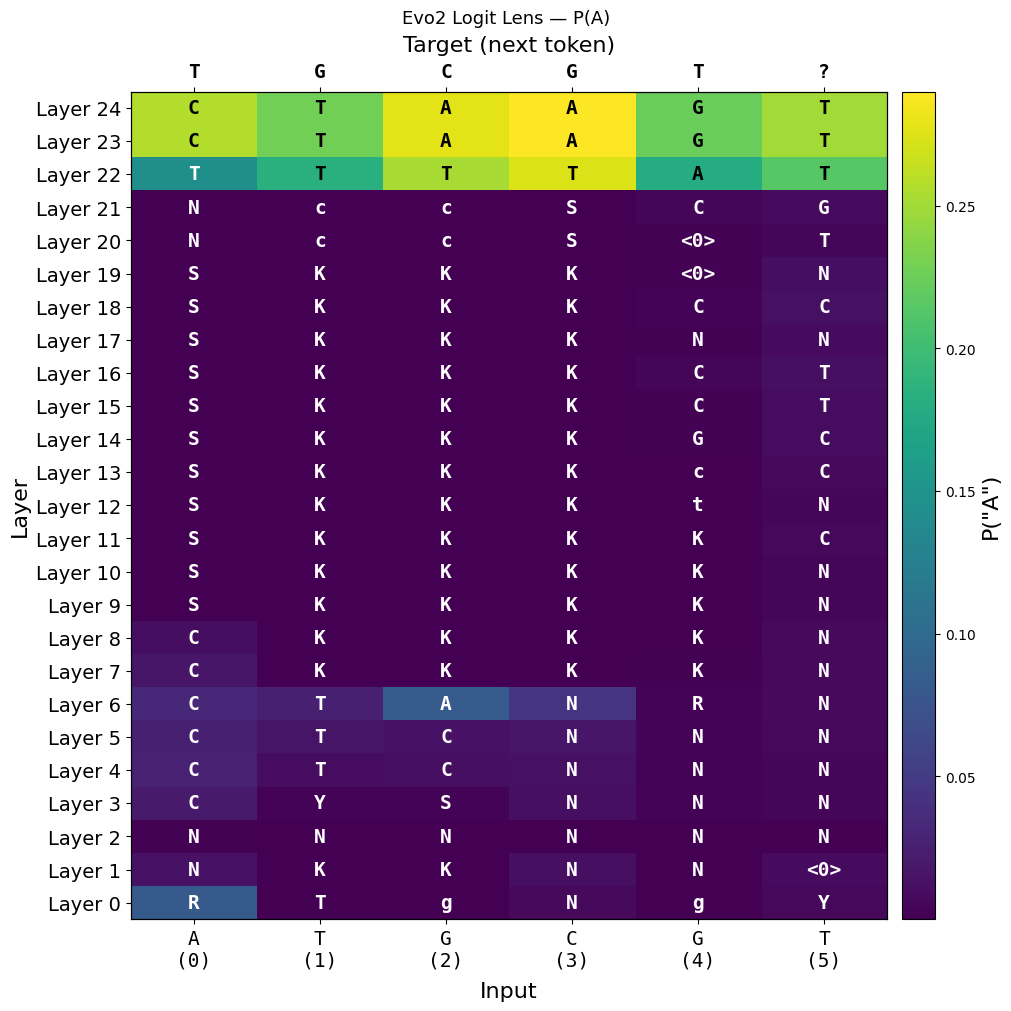

In [10]:
# Color by probability of a specific nucleotide, annotate with top-1 token
plot_logit_lens_evo2_annotated(sequence, results, target_char='A')

Saved to images/evo2_1b_base_logit_lens_avg.png


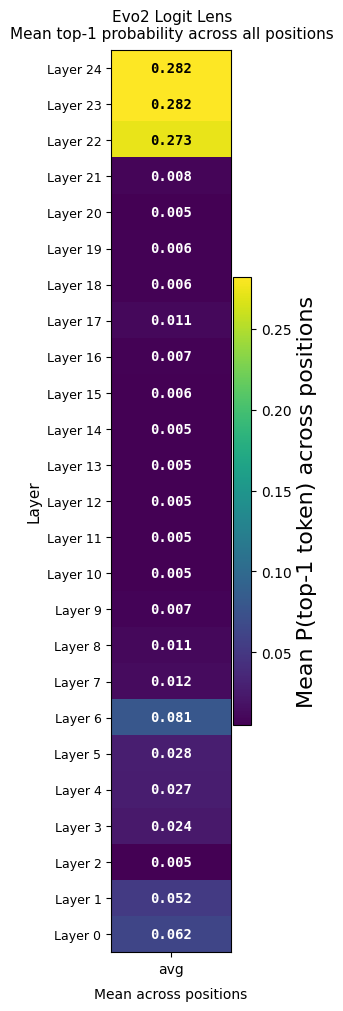

In [11]:
# Show top-20 tokens by average probability across all positions
plot_logit_lens_evo2_averaged(sequence, results, save_path=f"images/{mdl_id}_logit_lens_avg.png")


Loading evo2_1b_base...


Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Found complete file in repo: evo2_1b_base.pt


100%|██████████████████████████████████████████| 25/25 [00:00<00:00, 501.60it/s]


Extra keys in state_dict: {'blocks.17.mixer.dense._extra_state', 'unembed.weight', 'blocks.24.mixer.dense._extra_state', 'blocks.3.mixer.dense._extra_state', 'blocks.10.mixer.dense._extra_state'}


/scratch/ceresma/envs/evo2/lib/python3.11/site-packages/transformer_engine/pytorch/module/base.py:630: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(state

... (9 outputs left out)

100%|██████████████████████████████████████████| 50/50 [00:00<00:00, 100.39it/s]


Extra keys in state_dict: {'blocks.8.out_filter_dense._extra_state', 'blocks.6.mlp.l2._extra_state', 'blocks.14.out_filter_dense._extra_state', 'blocks.32.mlp.l3._extra_state', 'blocks.30.out_filter_dense._extra_state', 'blocks.40.out_filter_dense._extra_state', 'blocks.2.mlp.l2._extra_state', 'blocks.34.mlp.l1._extra_state', 'blocks.15.mlp.l3._extra_state', 'blocks.24.mixer.dense._extra_state', 'blocks.37.mlp.l1._extra_state', 'blocks.31.mixer.dense._extra_state', 'blocks.19.mlp.l2._extra_state', 'blocks.7.out_filter_dense._extra_state', 'blocks.46.mlp.l3._extra_state', 'blocks.1.mlp.l2._extra_state', 'blocks.34.out_filter_dense._extra_state', 'blocks.17.mlp.l1._extra_state', 'blocks.22.mlp.l1._extra_state', 'blocks.38.mlp.l2._extra_state', 'blocks.29.out_filter_dense._extra_state', 'blocks.25.mlp.l1._extra_state', 'blocks.35.mixer.attn._extra_state', 'blocks.35.mixer.dense._extra_state', 'blocks.45.mlp.l1._extra_state', 'blocks.25.out_filter_dense._extra_state', 'blocks.3.mlp.l2._ext

100%|██████████████████████████████████████████| 50/50 [00:00<00:00, 315.75it/s]


Extra keys in state_dict: {'blocks.8.out_filter_dense._extra_state', 'blocks.6.mlp.l2._extra_state', 'blocks.14.out_filter_dense._extra_state', 'blocks.32.mlp.l3._extra_state', 'blocks.30.out_filter_dense._extra_state', 'blocks.40.out_filter_dense._extra_state', 'blocks.2.mlp.l2._extra_state', 'blocks.34.mlp.l1._extra_state', 'blocks.15.mlp.l3._extra_state', 'blocks.24.mixer.dense._extra_state', 'blocks.37.mlp.l1._extra_state', 'blocks.31.mixer.dense._extra_state', 'blocks.19.mlp.l2._extra_state', 'blocks.7.out_filter_dense._extra_state', 'blocks.46.mlp.l3._extra_state', 'blocks.1.mlp.l2._extra_state', 'blocks.34.out_filter_dense._extra_state', 'blocks.17.mlp.l1._extra_state', 'blocks.22.mlp.l1._extra_state', 'blocks.38.mlp.l2._extra_state', 'blocks.29.out_filter_dense._extra_state', 'blocks.25.mlp.l1._extra_state', 'blocks.35.mixer.dense._extra_state', 'blocks.45.mlp.l1._extra_state', 'blocks.25.out_filter_dense._extra_state', 'blocks.3.mlp.l2._extra_state', 'blocks.16.out_filter_dens

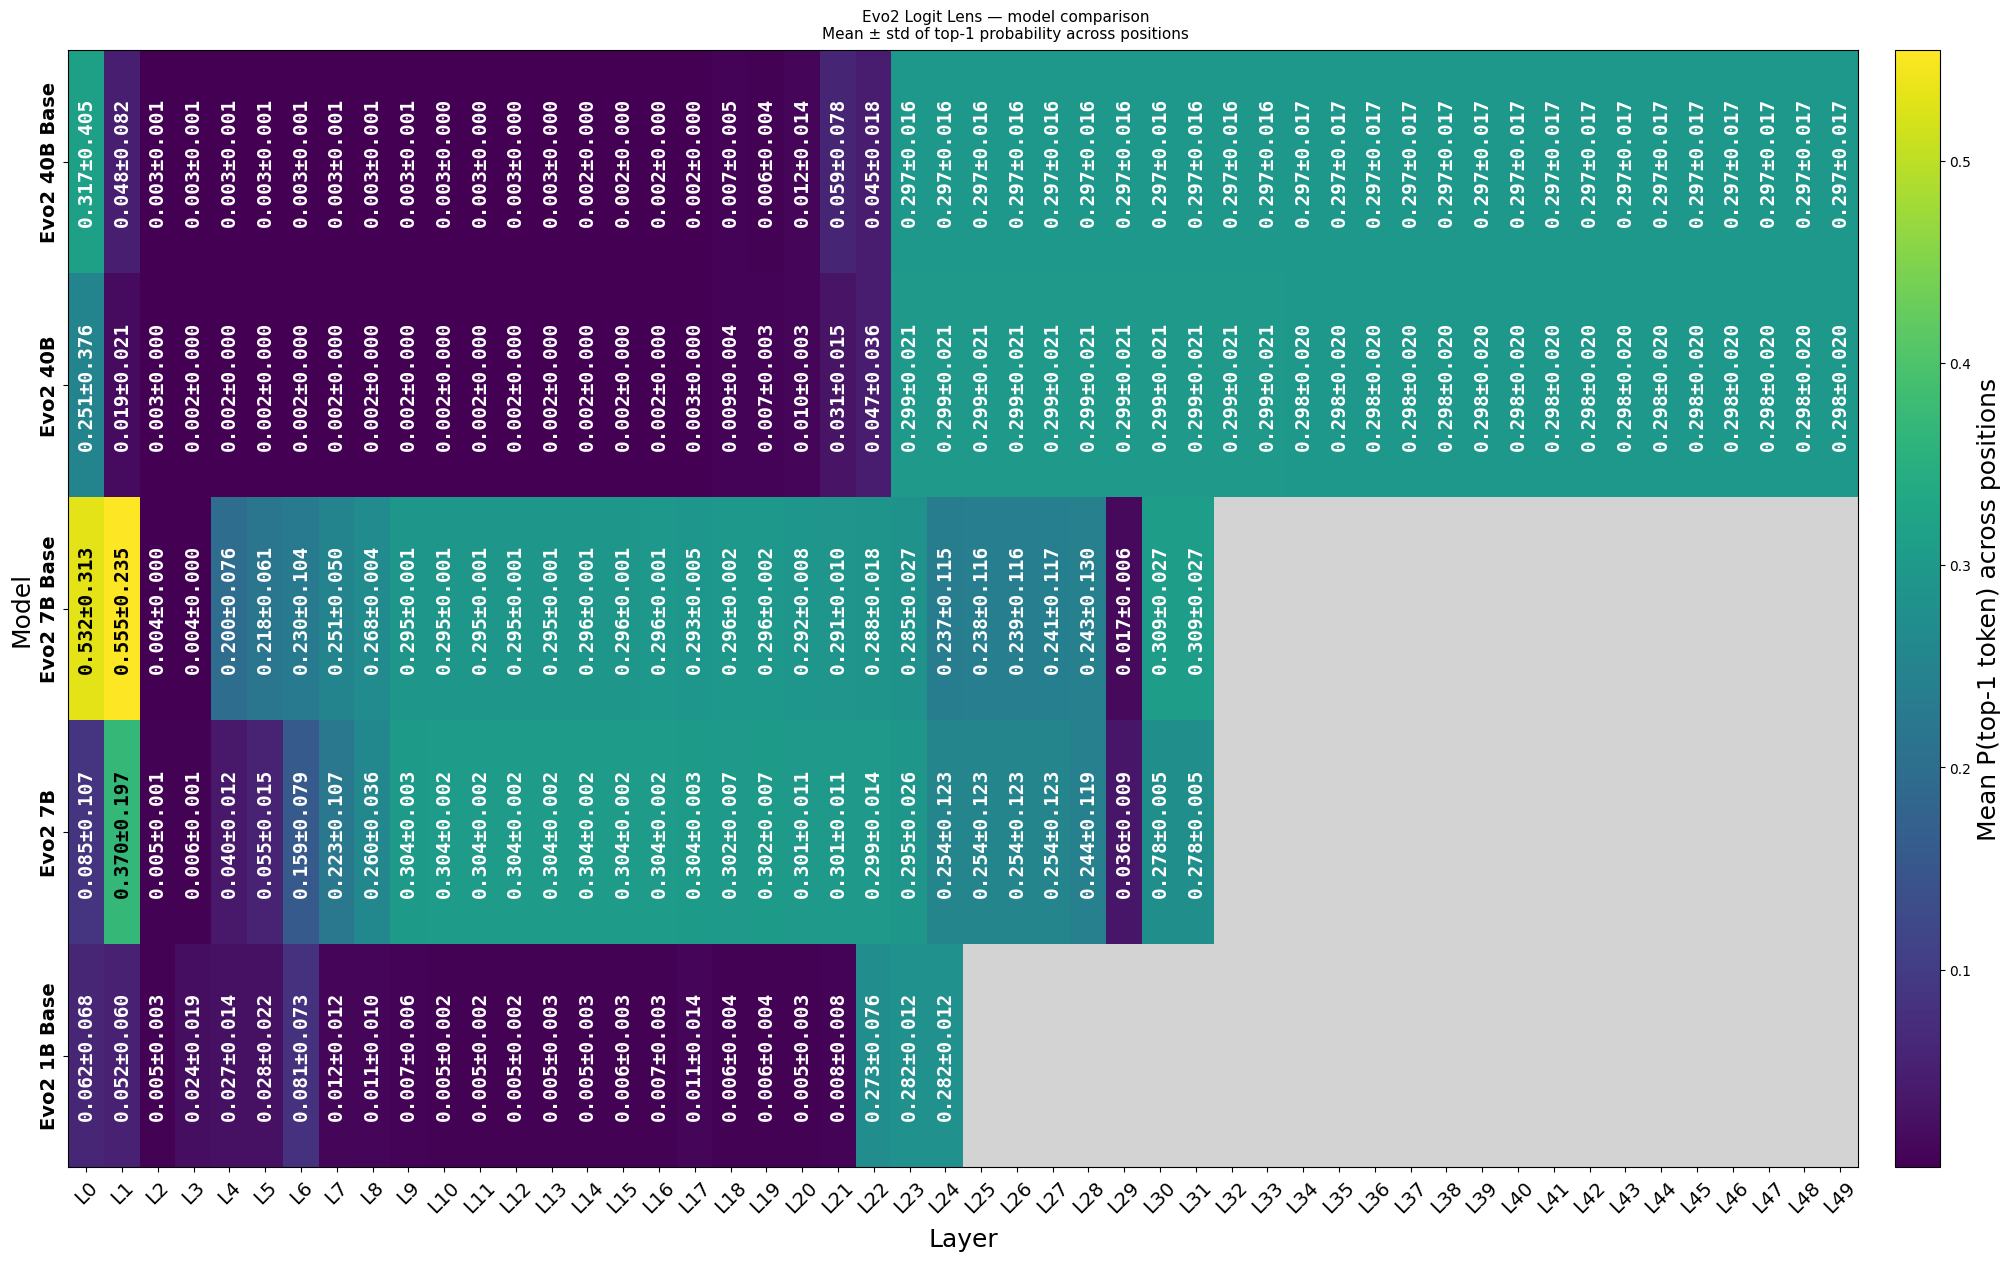

In [12]:
model_ids = ['evo2_1b_base', 'evo2_7b', 'evo2_7b_base', "evo2_40b", "evo2_40b_base"]

plot_logit_lens_multi_model(
    sequence, model_ids,
    annotate=True,
    agg='mean',
    save_path="images/multi_model_logit_lens_annot_h.png", 
    orientation='horizontal',
)


Loading evo2_1b_base...


Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Found complete file in repo: evo2_1b_base.pt


100%|██████████████████████████████████████████| 25/25 [00:00<00:00, 456.37it/s]


Extra keys in state_dict: {'blocks.17.mixer.dense._extra_state', 'unembed.weight', 'blocks.24.mixer.dense._extra_state', 'blocks.3.mixer.dense._extra_state', 'blocks.10.mixer.dense._extra_state'}


/scratch/ceresma/envs/evo2/lib/python3.11/site-packages/transformer_engine/pytorch/module/base.py:630: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(state

... (9 outputs left out)

100%|██████████████████████████████████████████| 50/50 [00:00<00:00, 330.20it/s]


Extra keys in state_dict: {'blocks.8.out_filter_dense._extra_state', 'blocks.6.mlp.l2._extra_state', 'blocks.14.out_filter_dense._extra_state', 'blocks.32.mlp.l3._extra_state', 'blocks.30.out_filter_dense._extra_state', 'blocks.40.out_filter_dense._extra_state', 'blocks.2.mlp.l2._extra_state', 'blocks.34.mlp.l1._extra_state', 'blocks.15.mlp.l3._extra_state', 'blocks.24.mixer.dense._extra_state', 'blocks.37.mlp.l1._extra_state', 'blocks.31.mixer.dense._extra_state', 'blocks.19.mlp.l2._extra_state', 'blocks.7.out_filter_dense._extra_state', 'blocks.46.mlp.l3._extra_state', 'blocks.1.mlp.l2._extra_state', 'blocks.34.out_filter_dense._extra_state', 'blocks.17.mlp.l1._extra_state', 'blocks.22.mlp.l1._extra_state', 'blocks.38.mlp.l2._extra_state', 'blocks.29.out_filter_dense._extra_state', 'blocks.25.mlp.l1._extra_state', 'blocks.35.mixer.attn._extra_state', 'blocks.35.mixer.dense._extra_state', 'blocks.45.mlp.l1._extra_state', 'blocks.25.out_filter_dense._extra_state', 'blocks.3.mlp.l2._ext

100%|██████████████████████████████████████████| 50/50 [00:00<00:00, 319.36it/s]


Extra keys in state_dict: {'blocks.8.out_filter_dense._extra_state', 'blocks.6.mlp.l2._extra_state', 'blocks.14.out_filter_dense._extra_state', 'blocks.32.mlp.l3._extra_state', 'blocks.30.out_filter_dense._extra_state', 'blocks.40.out_filter_dense._extra_state', 'blocks.2.mlp.l2._extra_state', 'blocks.34.mlp.l1._extra_state', 'blocks.15.mlp.l3._extra_state', 'blocks.24.mixer.dense._extra_state', 'blocks.37.mlp.l1._extra_state', 'blocks.31.mixer.dense._extra_state', 'blocks.19.mlp.l2._extra_state', 'blocks.7.out_filter_dense._extra_state', 'blocks.46.mlp.l3._extra_state', 'blocks.1.mlp.l2._extra_state', 'blocks.34.out_filter_dense._extra_state', 'blocks.17.mlp.l1._extra_state', 'blocks.22.mlp.l1._extra_state', 'blocks.38.mlp.l2._extra_state', 'blocks.29.out_filter_dense._extra_state', 'blocks.25.mlp.l1._extra_state', 'blocks.35.mixer.dense._extra_state', 'blocks.45.mlp.l1._extra_state', 'blocks.25.out_filter_dense._extra_state', 'blocks.3.mlp.l2._extra_state', 'blocks.16.out_filter_dens

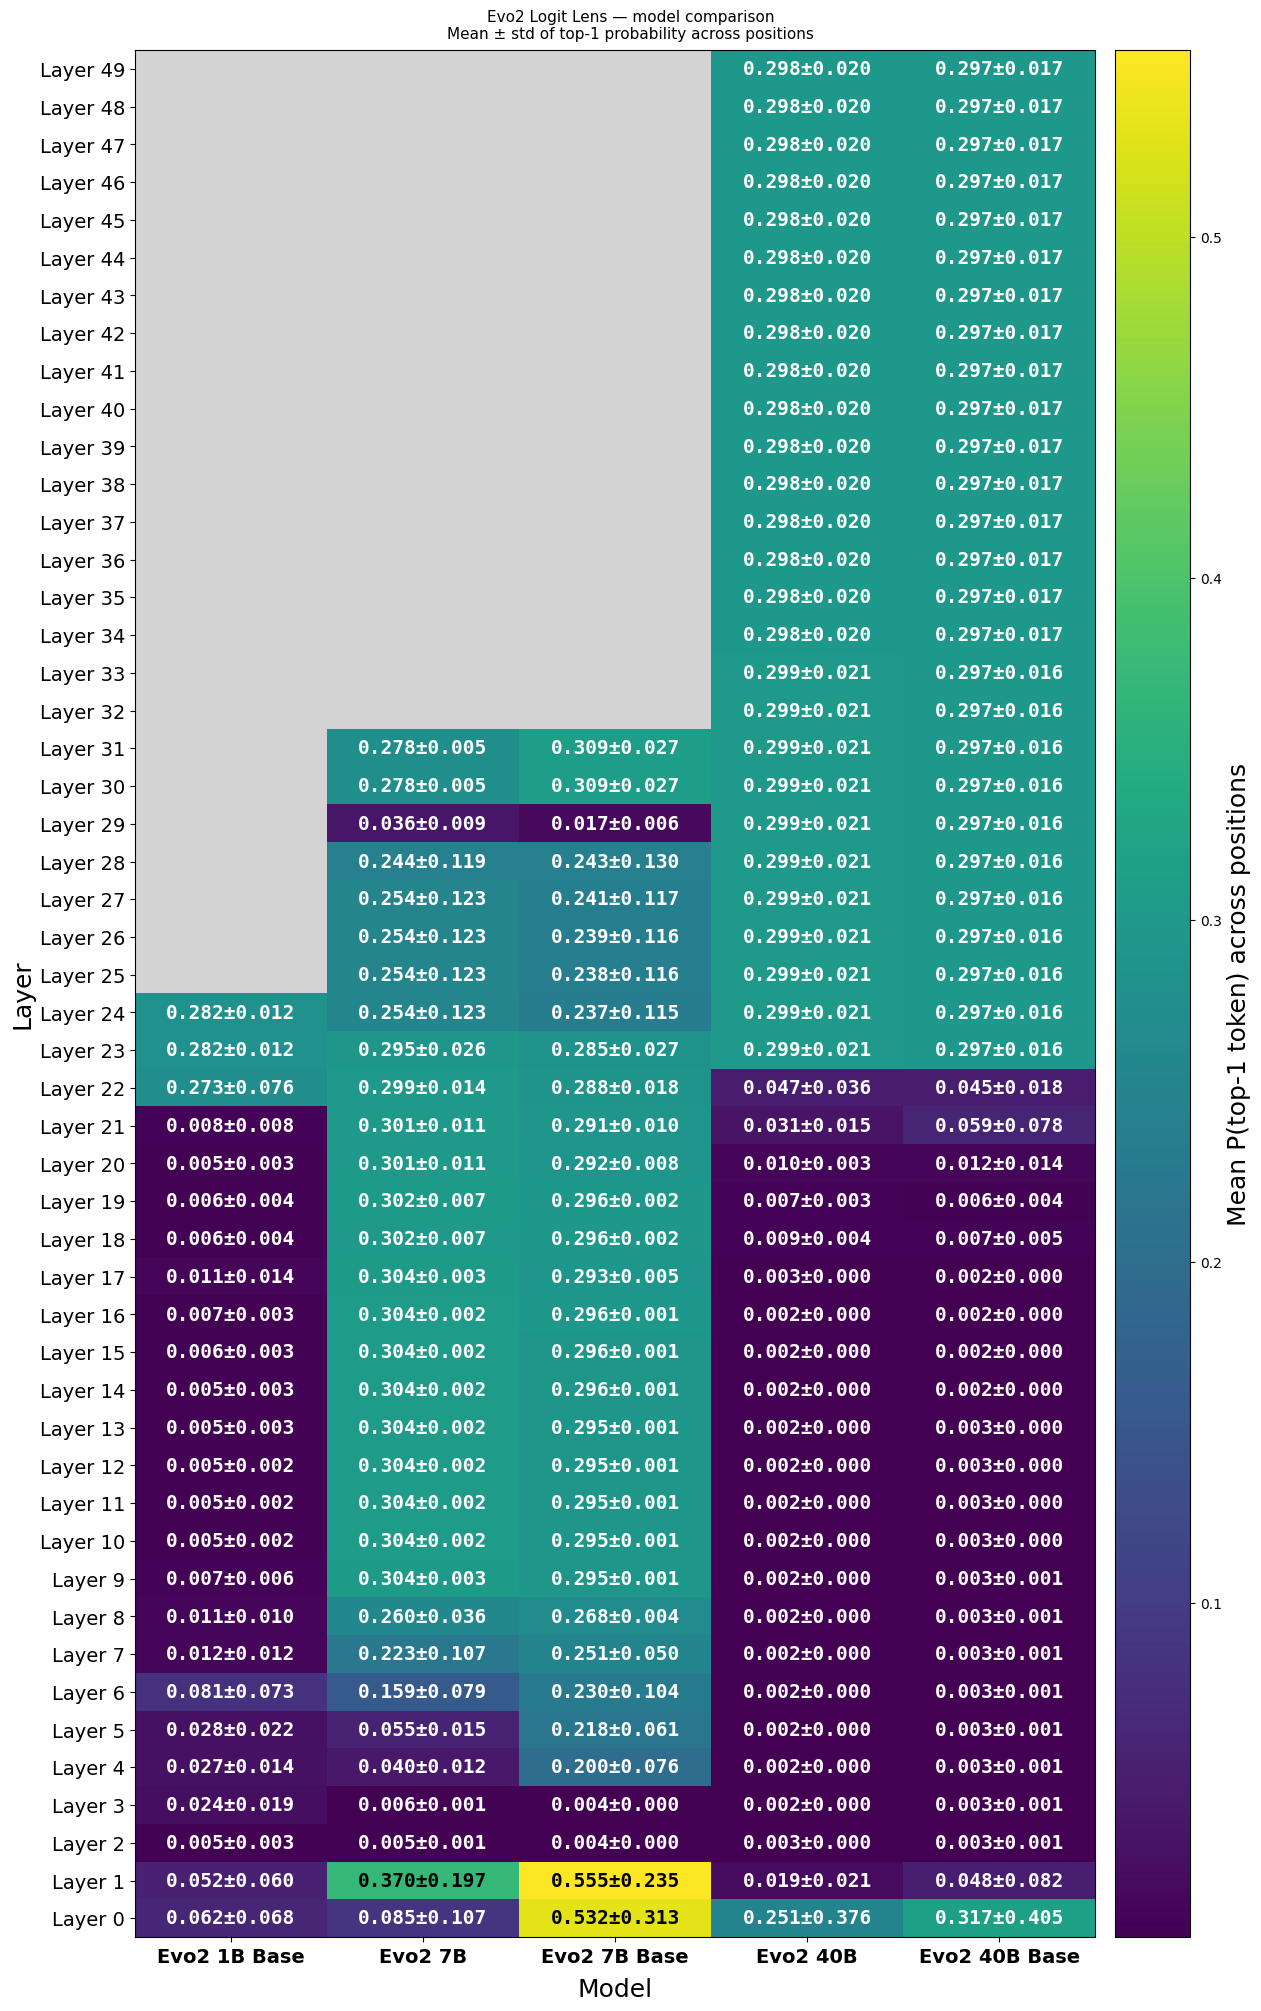

In [13]:
model_ids = ['evo2_1b_base', 'evo2_7b', 'evo2_7b_base', "evo2_40b", "evo2_40b_base"]

plot_logit_lens_multi_model(
    sequence, model_ids,
    annotate=True,
    agg='mean',
    save_path="images/multi_model_logit_lens_annot_v.png", 
    orientation='vertical',
)

In [14]:
if multi_seq_comp:
    # Path to your multi-FASTA file
    fasta_file = 'AMR.genes.fna'
    
    for idx, record in enumerate(SeqIO.parse(fasta_file, "fasta")):
        seq_id = record.id
        sequence = str(record.seq).upper()
        seq_length = len(sequence)
        
        plot_logit_lens_multi_model(
            sequence, model_ids,
            annotate=False,
            agg='mean',
            save_path=None,
            orientation='horizontal')
    
        if idx == 4:
            break